In [1]:
import sys
import os
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import scipy as sp

# sys.path.append(os.path.join(os.getcwd(), '../import_worm'))
sys.path.append(os.path.join(os.getcwd(), '../import'))

# noinspection PyUnresolvedReferences
from utils import read_utils
# noinspection PyUnresolvedReferences
from utils import plot_utils
# # noinspection PyUnresolvedReferences
# from utils import train_utils
#
# # noinspection PyUnresolvedReferences
# from models import bom
# # noinspection PyUnresolvedReferences
# from models import hgm

In [2]:
import importlib
importlib.reload(read_utils)
importlib.reload(plot_utils)
# importlib.reload(train_utils)
# importlib.reload(bom)
# importlib.reload(hgm)

<module 'utils.plot_utils' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/mouse-2019-stringer/data_exploration/../import/utils/plot_utils.py'>

In [3]:
read_ids = list(range(0, 8+1))
# read_ids = [3]
plot_id = 3

In [4]:
path = os.path.join(read_utils.get_data_path(), 'mouse-2019-stringer/6163622/sessions')

(file_ids, filenames,
 traces,
 motion_pcs,
 continuous_behaviors) = read_utils.get_data(path, read_ids)

In [5]:
# clear nan values
for i in range(len(file_ids)):
	# mask = motion_pcs[i][0].notna().all(axis=1)
	mask = continuous_behaviors[i].notna().all(axis=1)

	traces[i] = traces[i][mask]
	motion_pcs[i][0] = motion_pcs[i][0][mask]
	motion_pcs[i][1] = motion_pcs[i][1][mask]
	continuous_behaviors[i] = continuous_behaviors[i][mask]

# naive ID neurons
for i in range(len(file_ids)):
	traces[i].columns = pd.Index([
		f'{file_ids[i]:02d}_{n_id:03d}' for n_id in range(traces[i].shape[1])
	])

Text(0.5, 1.0, 'Neuronal activity')

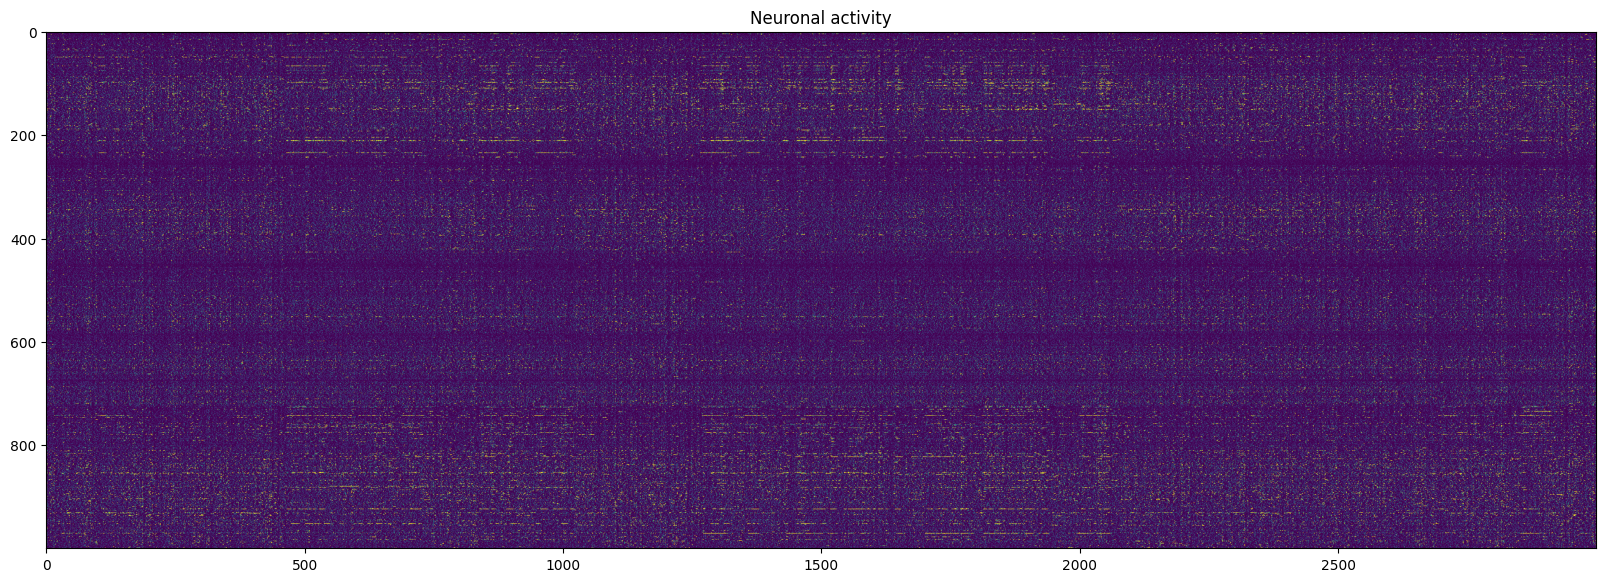

In [8]:
plt.figure(figsize=(20, 20))
plt.imshow(np.clip(traces[file_ids.index(plot_id)].values[:3000, :1000].T, 0, 500), cmap='viridis')
plt.title('Neuronal activity')

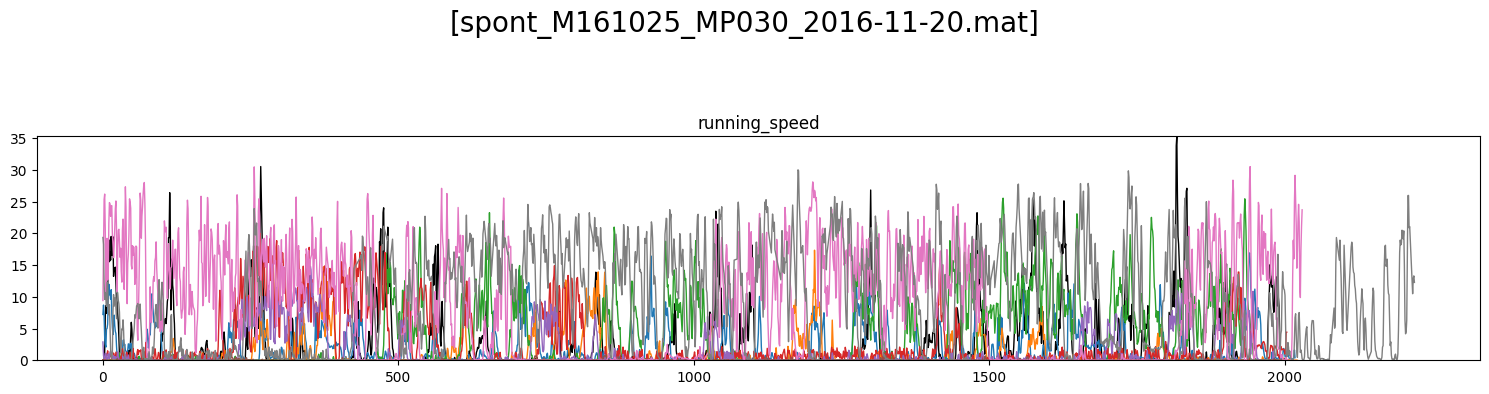

In [42]:
plot_utils.plot_traces(f'[{filenames[file_ids.index(plot_id)]}]',
					   [b[['running_speed']].iloc[:2000] for b in continuous_behaviors],
					   plots_per_row=1, ylimits=None)

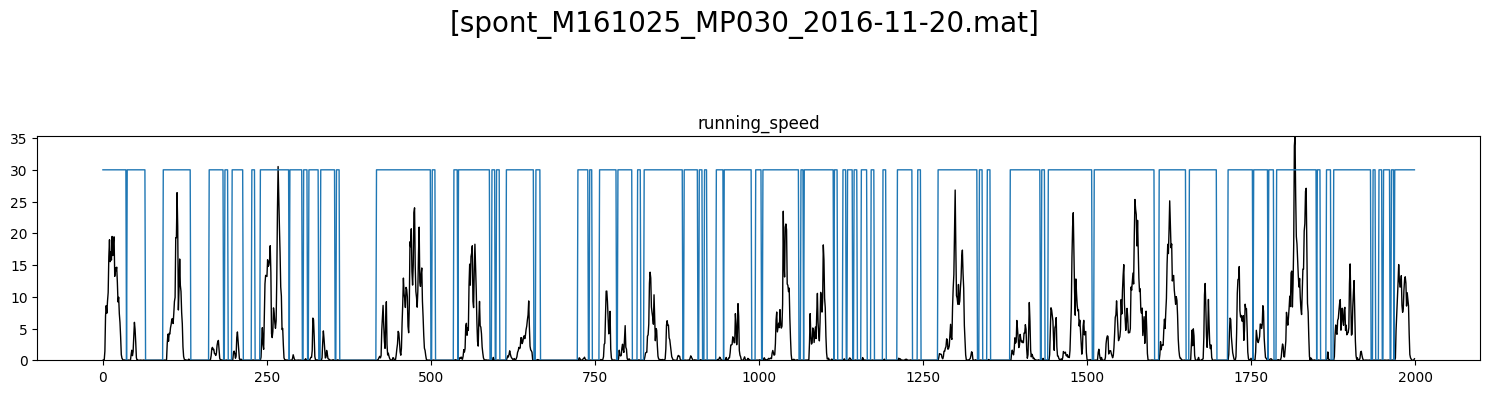

In [41]:
classes = continuous_behaviors[0][['running_speed']].values > np.quantile(continuous_behaviors[0][['running_speed']].values, 0.05)

plot_utils.plot_traces(f'[{filenames[file_ids.index(plot_id)]}]',
					   [continuous_behaviors[0][['running_speed']].iloc[:2000],
						pd.DataFrame(data=classes[:2000] * 30, columns=continuous_behaviors[0][['running_speed']].columns)],
					   plots_per_row=1, ylimits=None)

In [ ]:
threshold = np.quantile(continuous_behaviors[i][['running_speed']], 0.05)
classes = np.where(continuous_behaviors[i][['running_speed']].values > threshold)
splits = list(StratifiedKFold(n_splits=5, shuffle=False).split(np.zeros(traces[i].shape[0]), classes))

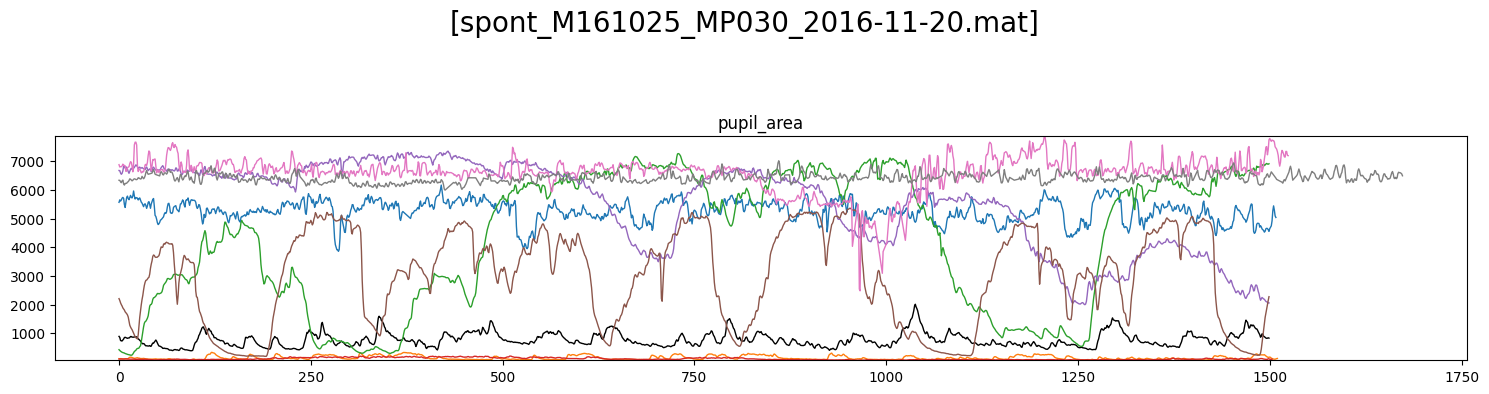

In [8]:
plot_utils.plot_traces(f'[{filenames[file_ids.index(plot_id)]}]',
					   [b[['pupil_area']].iloc[:1500] for b in continuous_behaviors],
					   plots_per_row=1, ylimits=None)

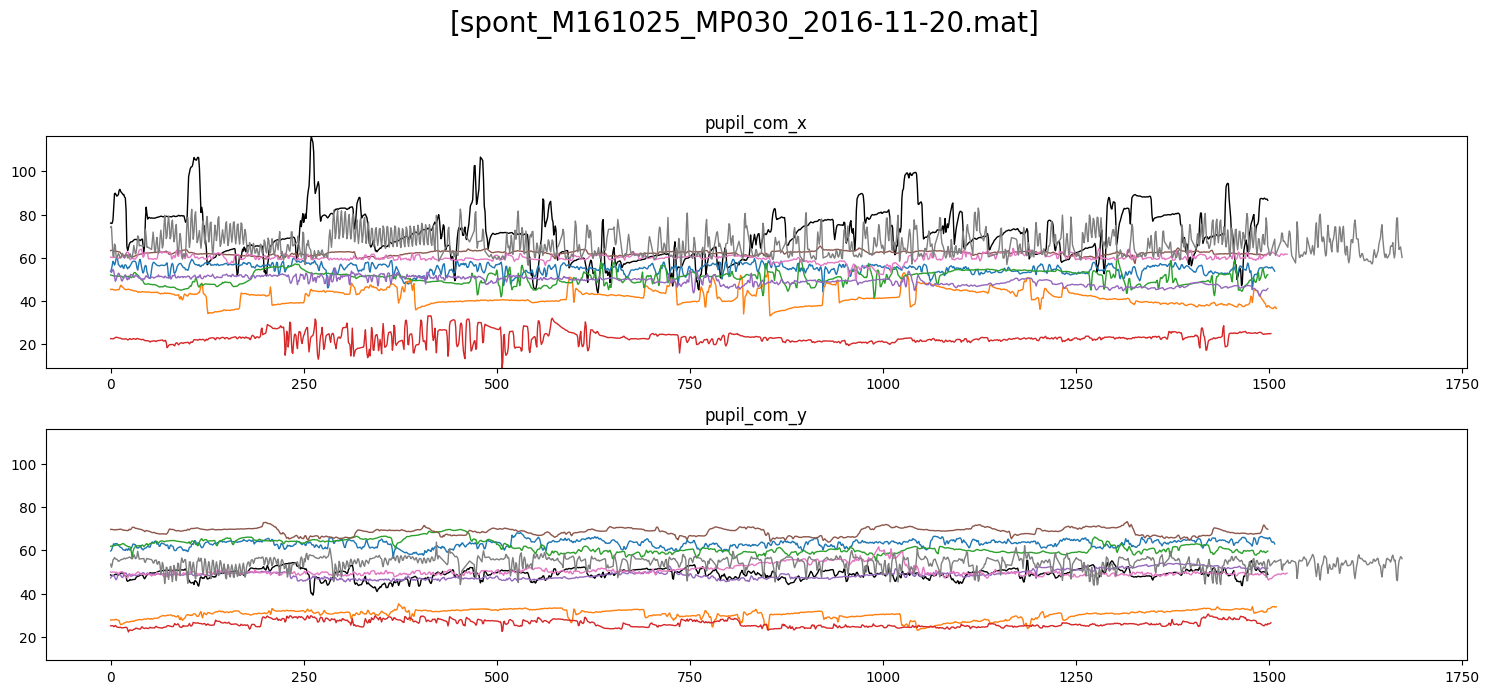

In [9]:
plot_utils.plot_traces(f'[{filenames[file_ids.index(plot_id)]}]',
					   [b[['pupil_com_x', 'pupil_com_y']].iloc[:1500] for b in continuous_behaviors],
					   plots_per_row=1, ylimits=None)

Text(0.5, 1.0, 'pupil com x (blue) and pupil com y (orange)')

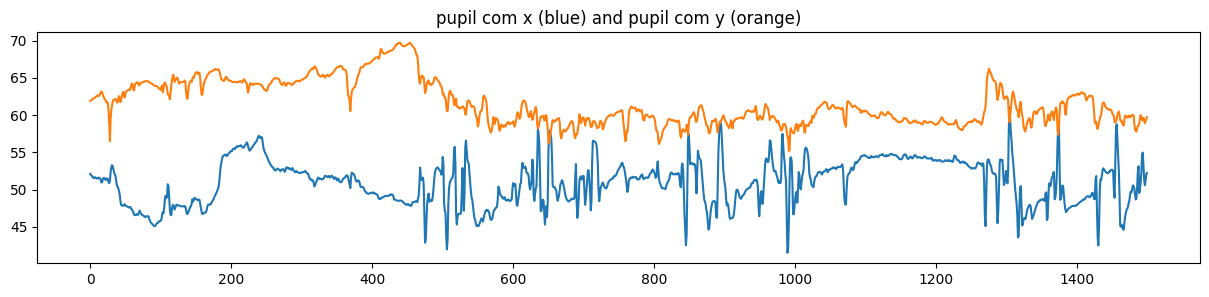

In [10]:
plt.figure(figsize=(15, 3))
plt.plot()
plt.plot(continuous_behaviors[file_ids.index(plot_id)]['pupil_com_x'].iloc[:1500])
plt.plot(continuous_behaviors[file_ids.index(plot_id)]['pupil_com_y'].iloc[:1500])
plt.title('pupil com x (blue) and pupil com y (orange)')

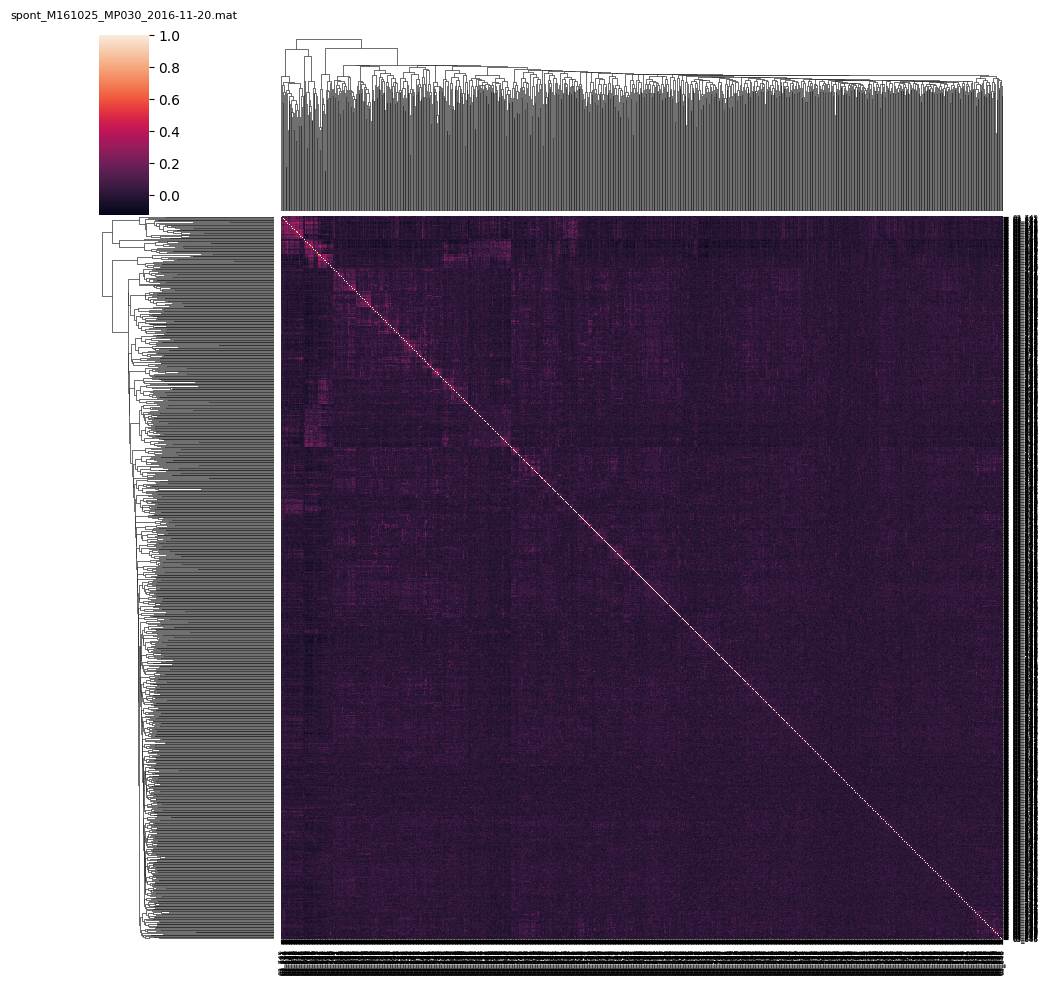

In [11]:
correlation = traces[file_ids.index(plot_id)].iloc[:1500, :1000].corr()
heatmap = sns.clustermap(correlation, yticklabels=True, xticklabels=True)
heatmap.ax_heatmap.set_yticklabels(heatmap.ax_heatmap.get_yticklabels(), fontsize=5)
heatmap.ax_heatmap.set_xticklabels(heatmap.ax_heatmap.get_xticklabels(), fontsize=5)
heatmap.ax_heatmap.tick_params(axis='x', bottom=True, top=False)

plt.title(f'{filenames[file_ids.index(plot_id)]}', y=1.05, fontsize=8)
plt.show()

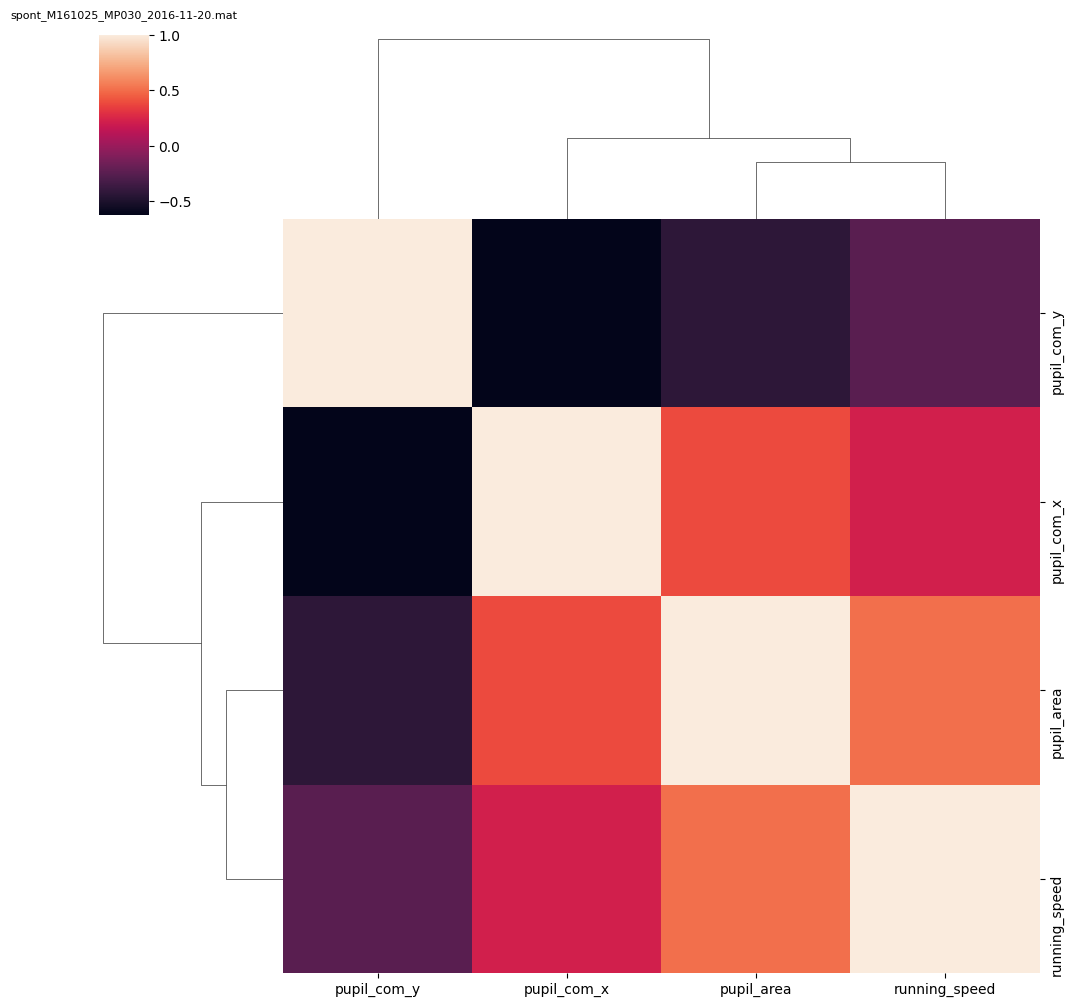

In [12]:
correlation = continuous_behaviors[file_ids.index(plot_id)].corr()
heatmap = sns.clustermap(correlation, yticklabels=True, xticklabels=True)
heatmap.ax_heatmap.set_yticklabels(heatmap.ax_heatmap.get_yticklabels(), fontsize=10)
heatmap.ax_heatmap.set_xticklabels(heatmap.ax_heatmap.get_xticklabels(), fontsize=10)
heatmap.ax_heatmap.tick_params(axis='x', bottom=True, top=False)

plt.title(f'{filenames[file_ids.index(plot_id)]}', y=1.05, fontsize=8)
plt.show()

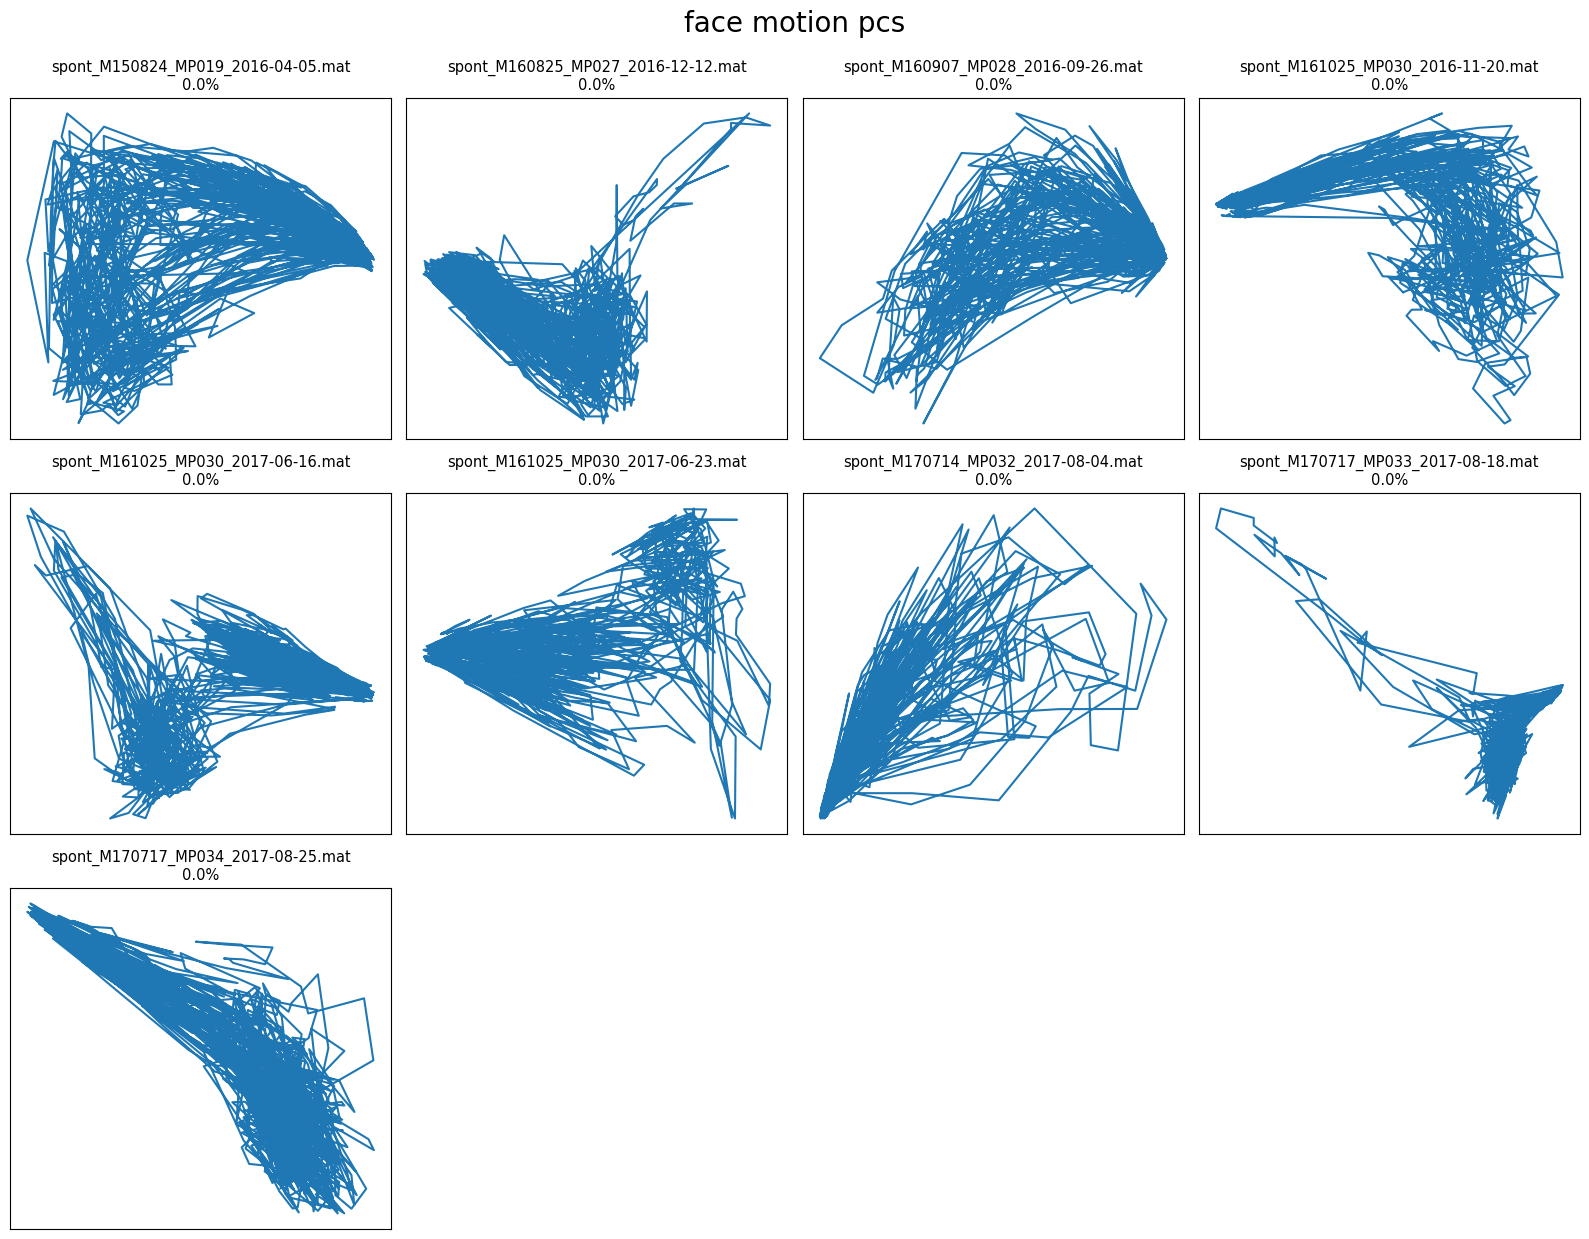

0.0%


In [13]:
plot_utils.plot_manifolds(filenames, [motion_pc[0][['PC1', 'PC2']].iloc[:1500] for motion_pc in motion_pcs], [[0] for _ in range(len(filenames))],
						  title='face motion pcs', top_space=0.25)

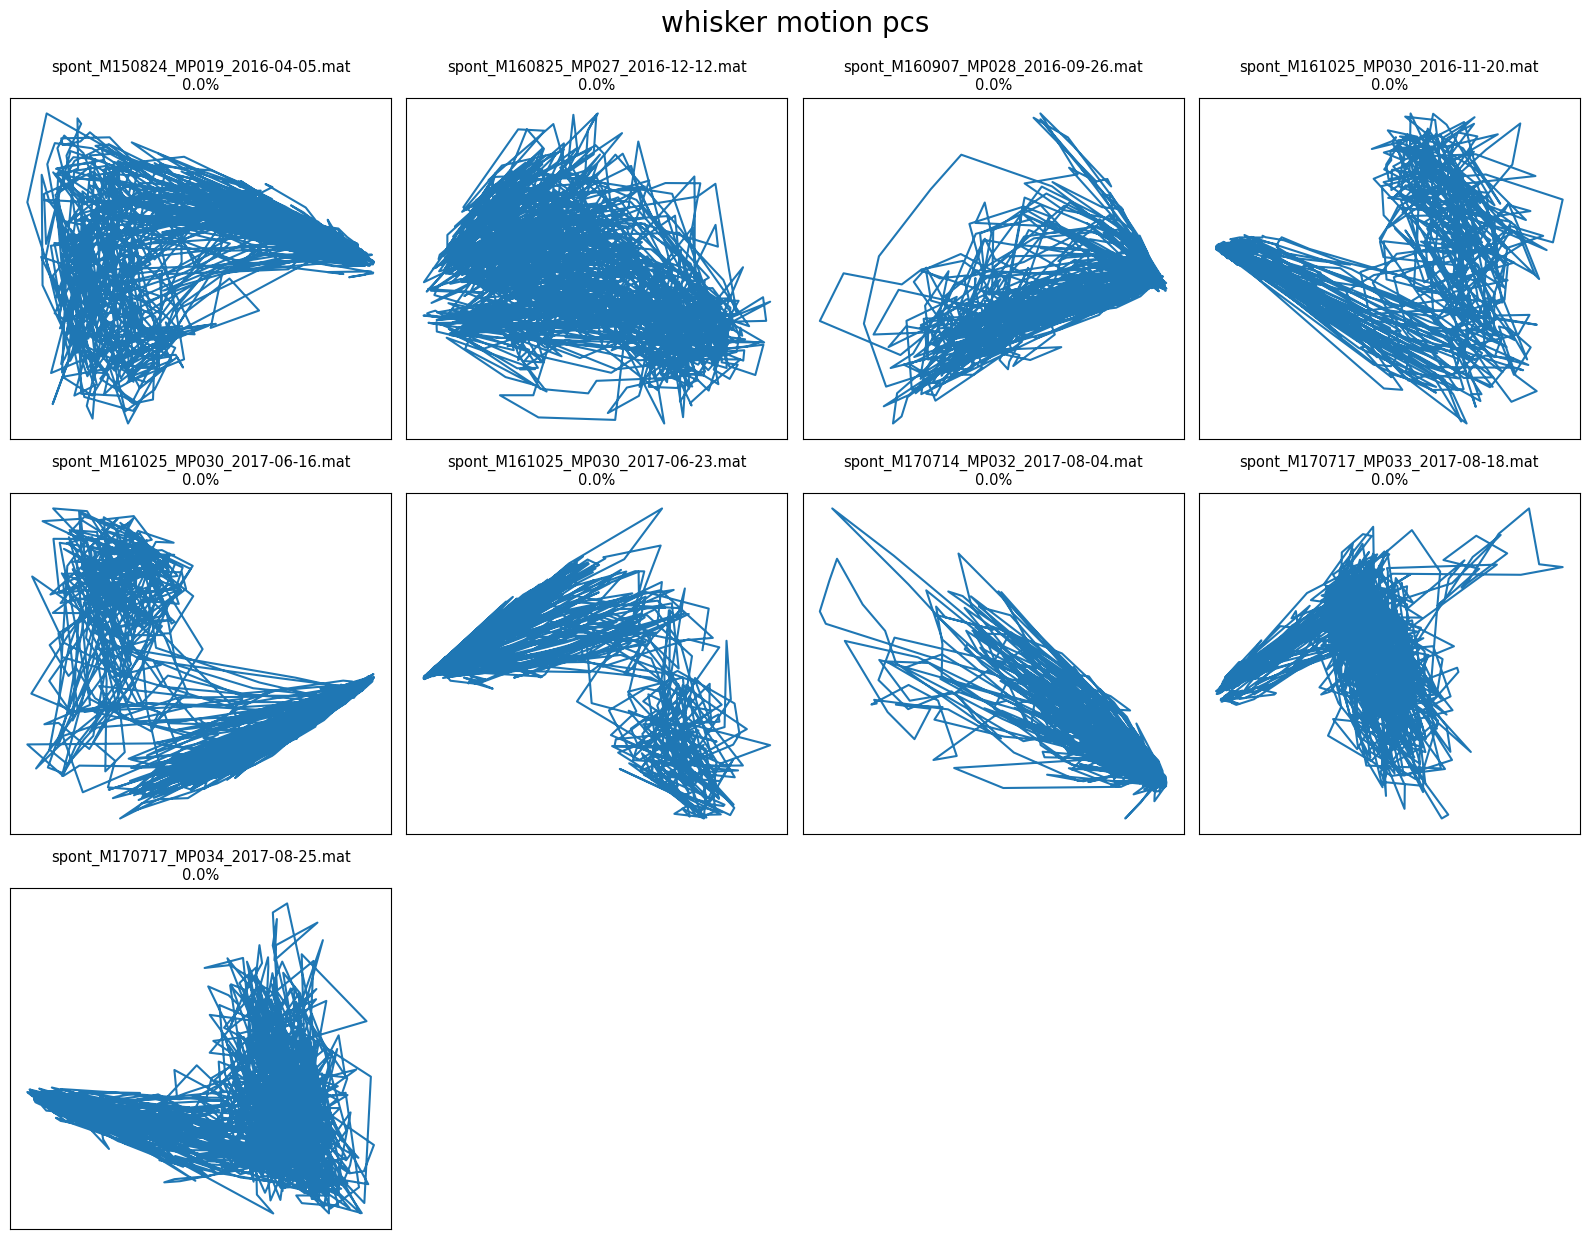

0.0%


In [14]:
plot_utils.plot_manifolds(filenames, [motion_pc[1][['PC1', 'PC2']].iloc[:1500] for motion_pc in motion_pcs], [[0] for _ in range(len(filenames))],
						  title='whisker motion pcs', top_space=0.25)

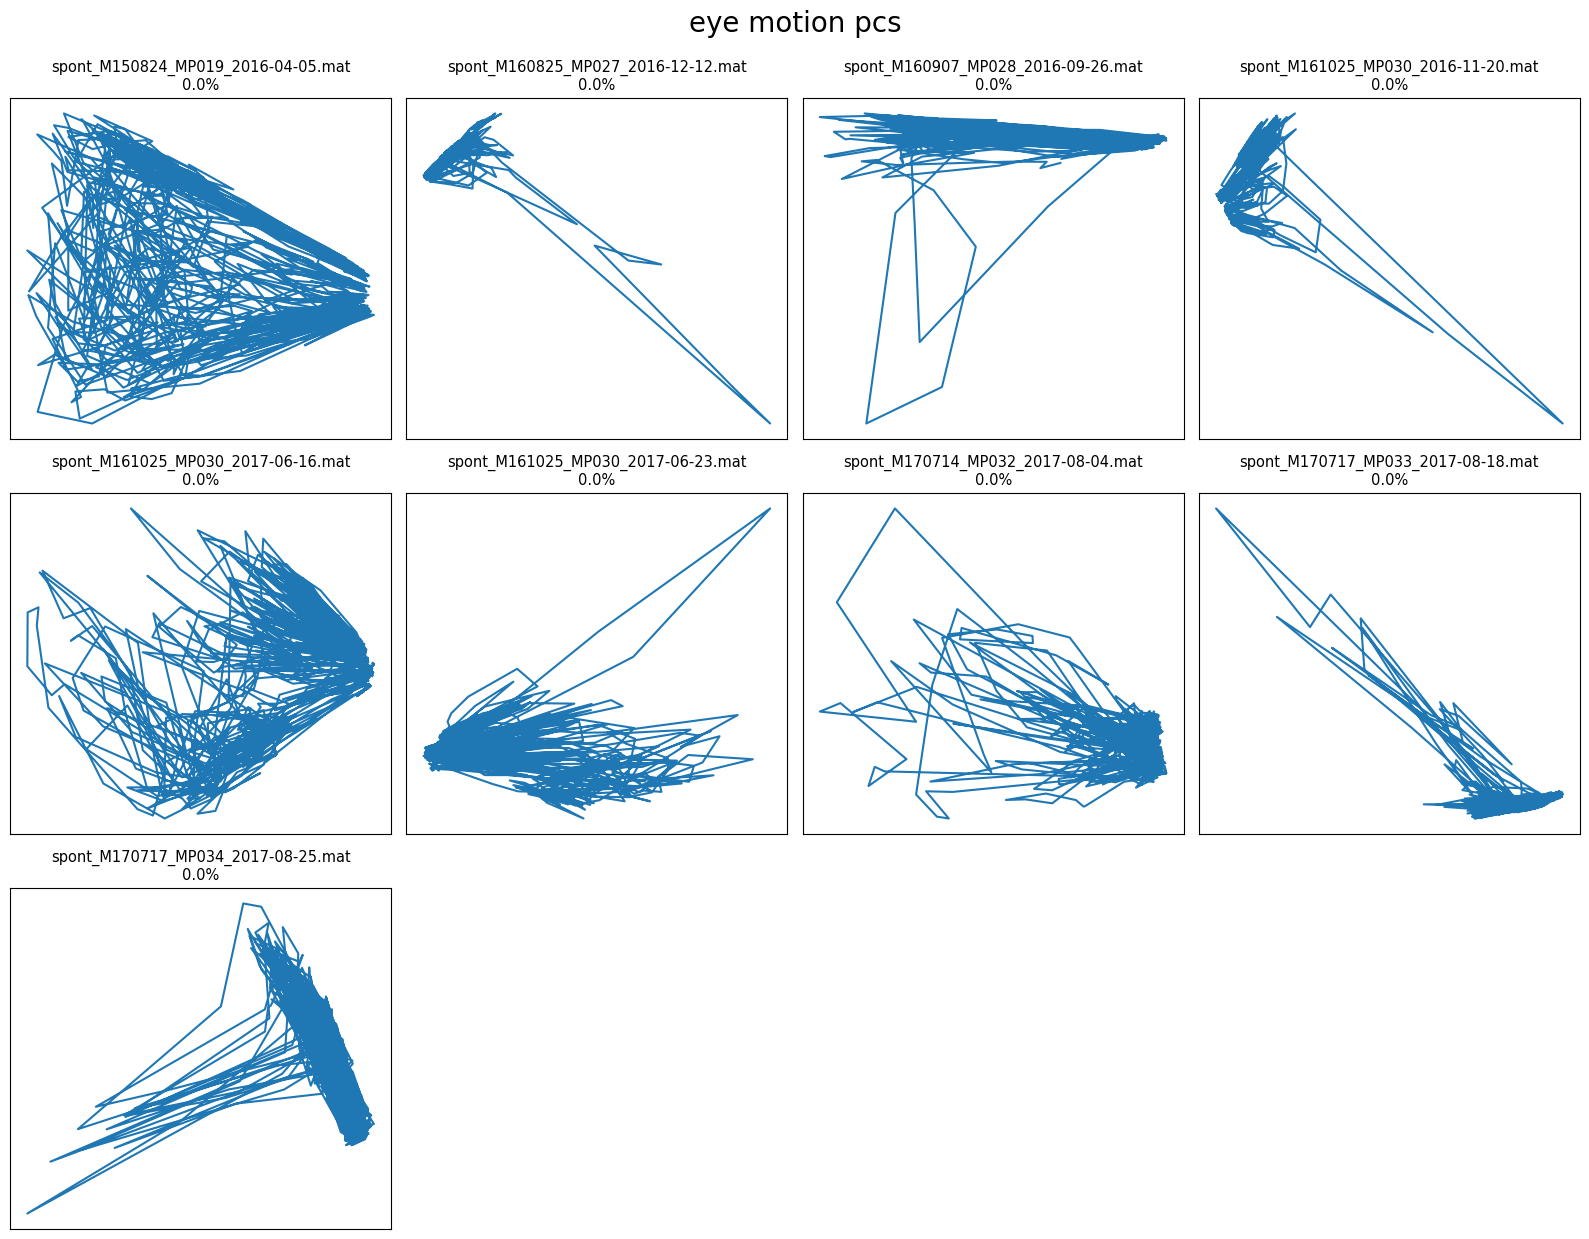

0.0%


In [15]:
plot_utils.plot_manifolds(filenames, [motion_pc[2][['PC1', 'PC2']].iloc[:1500] for motion_pc in motion_pcs], [[0] for _ in range(len(filenames))],
						  title='eye motion pcs', top_space=0.25)